# Data Prepation 4: Preprocessing

### 1. Encode non numeric feature columns and normalize numeric features

In [26]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# read data from csv
debris_df = pd.read_csv('../Data/Combined.csv')
debris_df.head()

,NORAD_CAT_ID,INTLDES,SATNAME,OBJECT_TYPE,COUNTRY,SITE,LAUNCH,EPOCH,PERIAPSIS,APOAPSIS,...,INCLINATION,RA_OF_ASC_NODE,MEAN_ANOMALY,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD,LIFETIME
0,23,1959-009B,JUNO II R/B,ROCKET BODY,US,AFETR,1959-10-13,1982-01-13 15:21:06.439968,506.194,762.990,...,50.3043,233.6360,61.7000,16909.0,0.000982,0.000093,0.0,7012.727,97.406,10869 days
1,28,1960-002A,THOR ABLE R/B,ROCKET BODY,US,AFETR,1960-04-01,1987-09-12 00:12:35.555904,600.706,625.344,...,48.3748,236.4746,264.6079,46764.0,0.000080,0.000006,0.0,6991.160,96.957,11415 days
2,30,1960-003A,THOR ABLESTAR R/B,ROCKET BODY,US,AFETR,1960-04-13,1961-04-17 11:27:12.924288,287.445,456.763,...,51.2500,272.4964,155.8967,5670.0,0.000000,0.001202,0.0,6750.239,91.989,492 days
3,33,1960-003C,THOR ABLESTAR DEB,DEBRIS,US,AFETR,1960-04-13,1960-08-06 21:56:44.331935,285.231,618.180,...,51.2879,72.6448,30.5053,1770.0,0.000000,0.000019,0.0,6829.840,93.621,95 days
4,35,1960-005B,SL-3 R/B,ROCKET BODY,CIS,TTMTR,1960-05-15,1960-06-08 00:20:02.506559,302.454,323.852,...,64.8899,183.4791,307.4432,380.0,0.000000,0.001764,0.0,6691.288,90.787,63 days


In [27]:
# convert Launch and Epoch to numeric timestamps
debris_df['LAUNCH'] = pd.to_datetime(debris_df['LAUNCH'])
debris_df['EPOCH'] = pd.to_datetime(debris_df['EPOCH'])

# convert Lifetime to number of days
debris_df["LIFETIME"] = pd.to_timedelta(debris_df["LIFETIME"]).dt.days

In [28]:
# define feature and label columns
feature_columns = ['OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', 'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD']
label_column = 'LIFETIME'

x = debris_df[feature_columns]
y = debris_df[label_column]

In [29]:
# split data into train and test
from sklearn.model_selection import train_test_split

# 80% training, 20% testing
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [30]:
# encode non numerical columns using One Hot Encoding 
from sklearn.preprocessing import OneHotEncoder

categorical_cols = x_train.select_dtypes(include=["object"]).columns.tolist()

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
x_train_encoded = encoder.fit_transform(x_train[categorical_cols]) # only fit the encoder to training dataset to avoid data leakage
x_test_encoded = encoder.transform(x_test[categorical_cols])

# convert to dataframes
encoded_cols = encoder.get_feature_names_out(categorical_cols)
x_train_encoded = pd.DataFrame(x_train_encoded, columns=encoded_cols, index=x_train.index)
x_test_encoded = pd.DataFrame(x_test_encoded, columns=encoded_cols, index=x_test.index)

# print columns 
print("Encoded categorical columns:")
for col in categorical_cols:
    print(f"- {col}")

Encoded categorical columns:
- OBJECT_TYPE
- COUNTRY
- SITE


In [31]:
# Normalize numeric columns
from sklearn.preprocessing import StandardScaler
import numpy as np

numeric_cols = x_train.select_dtypes(include=[np.number]).columns.tolist()

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train[numeric_cols]) # only fit scaler on training set to avoid data leakage
x_test_scaled = scaler.transform(x_test[numeric_cols])

# convert to dataframes
x_train_scaled = pd.DataFrame(x_train_scaled, columns=numeric_cols, index=x_train.index)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=numeric_cols, index=x_test.index)


# print columns
print("Scaled numeric columns:")
for col in numeric_cols:
    print(f"- {col}")

Scaled numeric columns:
- PERIAPSIS
- APOAPSIS
- ARG_OF_PERICENTER
- MEAN_MOTION
- ECCENTRICITY
- INCLINATION
- RA_OF_ASC_NODE
- MEAN_ANOMALY
- REV_AT_EPOCH
- BSTAR
- MEAN_MOTION_DOT
- MEAN_MOTION_DDOT
- SEMIMAJOR_AXIS
- PERIOD


In [32]:
# combinde encoded and normalized features
x_train_final = pd.concat([x_train_encoded, x_train_scaled], axis=1)
x_test_final = pd.concat([x_test_encoded, x_test_scaled], axis=1)

In [41]:
# save to csv
x_train_final["LIFETIME"] = y_train
x_test_final["LIFETIME"] = y_test

x_train_final.to_csv("../Data/TrainPreprocessed.csv", index=False)
x_test_final.to_csv("../Data/TestPreprocessed.csv", index=False)

### 2. Analyze Lifetime

In [33]:
# check datatypes
print(debris_df.dtypes)

NORAD_CAT_ID                  int64
INTLDES                      object
SATNAME                      object
OBJECT_TYPE                  object
COUNTRY                      object
SITE                         object
LAUNCH               datetime64[ns]
EPOCH                datetime64[ns]
PERIAPSIS                   float64
APOAPSIS                    float64
ARG_OF_PERICENTER           float64
MEAN_MOTION                 float64
ECCENTRICITY                float64
INCLINATION                 float64
RA_OF_ASC_NODE              float64
MEAN_ANOMALY                float64
REV_AT_EPOCH                float64
BSTAR                       float64
MEAN_MOTION_DOT             float64
MEAN_MOTION_DDOT            float64
SEMIMAJOR_AXIS              float64
PERIOD                      float64
LIFETIME                      int64
dtype: object


In [34]:
# summary statistics of lifetime
print(debris_df['LIFETIME'].describe())

count    10420.000000
mean      1872.665067
std       3411.639121
min          0.000000
25%         17.000000
50%        264.500000
75%       2134.500000
max      23115.000000
Name: LIFETIME, dtype: float64


In [35]:
# summary statistics of lifetime in years
lifetime_years = debris_df['LIFETIME'] / 365.25 # account for leap years
print(lifetime_years.describe())

count    10420.000000
mean         5.127078
std          9.340559
min          0.000000
25%          0.046543
50%          0.724162
75%          5.843943
max         63.285421
Name: LIFETIME, dtype: float64


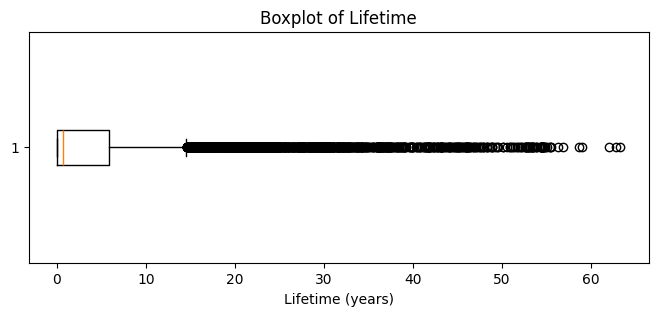

In [37]:
# create a boxplot of the lifetime in years
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 3))
plt.boxplot(debris_df['LIFETIME']/ 365.25, vert=False)
plt.xlabel('Lifetime (years)')
plt.title('Boxplot of Lifetime')
plt.show()


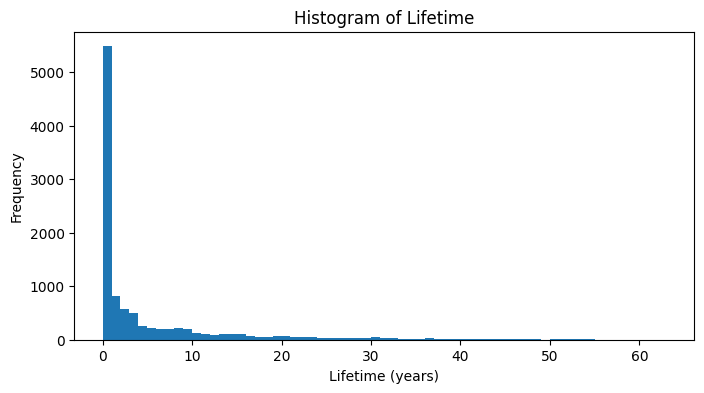

In [38]:
# create histogram of lifetime in years
import numpy as np
plt.figure(figsize=(8, 4))
plt.hist(debris_df['LIFETIME']/365, bins=np.arange(0, max(debris_df['LIFETIME']/365), 1))
plt.xlabel('Lifetime (years)')
plt.ylabel('Frequency')
plt.title('Histogram of Lifetime')
plt.show()


In [39]:
# count objects that have lifetime of less than 365 days
print("Objects with lifetime shorter than one year: ", debris_df[debris_df['LIFETIME'] < 365].shape[0])

Objects with lifetime shorter than one year:  5486


#### It could make sense to drop objects with a lifetime of one year or less but since in this all objects shall be considered, they will stay in the dataset.
